# Blackbody vs NewEra star: what changes in the main results

The same analyses with the two stellar SEDs of the pipeline, everything else identical: a **blackbody** at $T_{\rm eff}$ (the pre-2026-11-04 pipeline) and the **NewEra** model atmosphere (Hauschildt et al. 2025) at each host's $T_{\rm eff}$, log g and [Fe/H] (`astro_utils.STELLAR_MODEL = "newera"`, built and validated in `NewEra/build_newera.ipynb`). The SED is switched per analysis through `stellar_model` (`FittingConfig.stellar_model`, or the `stellar_model` argument of the phase-curve functions), so neither run depends on the repo default.

The stellar SED enters only the normalisation of the thermal emission (SPIDERMAN's stellar grid, $F_p/F_\star$) and `T_bright`. The bolometric insolation ($\sigma T_{\rm eff}^4$), the grey reflected light and the transit do not depend on it. Every thermal curve therefore changes by one factor per star and band, $k = S_{\rm BB}/S_{\rm NewEra}$ (in-band stellar flux of the blackbody over that of the model). That gives the expectations to check against below:
- thermal depths and curves scale by $k$; the reflected part does not;
- the $A_B$ and $F$ biases are unchanged in thermal-only fits and change only slightly when reflected light is included (its weight relative to the thermal part changes);
- the Fisher $\sigma$ scales as $1/k$, so significances (bias/$\sigma$, $z_F$) scale with $k$ and $\Delta\chi^2$ with $k^2$;
- `T_bright` of a model depth is the same with either star; `T_bright` of a **measured** depth is not.

The noise levels come from PandExo, which uses its own stellar spectrum normalised to the host's magnitude, so they do not depend on this choice. They are computed once and used for both stellar models.

In [1]:
import numpy as np
import os
import contextlib, io
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
from simple_bias_analysis import *
from HItargets_utils import *
from paper_plot_utils import paper_figure
import newera_utils

AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')
set_plot_style()

In [2]:
# The two stellar SEDs compared (label -> stellar_model)
MODELS = {"blackbody star": "blackbody", "NewEra star": "newera"}
BB, NE = MODELS

planet = hi_planets_by_name("TOI-2431 b")   # target of the per-instrument sections
INSTRUMENTS = JWST_RETRIEVALS   # the JWST bands singly, plus one joint fit of the two NIRSpec arrays (the tuple)
SINGLE = [ins for ins in INSTRUMENTS if isinstance(ins, str)]   # single detectors: the per-band quantities (k, curves, depths)

# baseline settings (HItargets_utils.py)
A_B_true = DEFAULT_A_B
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B
u, u_B = DEFAULT_U, DEFAULT_U_B           # transit and irradiance limb darkening
n_bins, n_orbits = DEFAULT_N_BINS, DEFAULT_N_ORBITS
kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)

# one cfg per stellar model; instrument_retrievals / instrument_cfg swap in each band, the stellar grid follows (FittingConfig.__post_init__)
cfgs = {lab: FittingConfig(planet=planet, filter_path=filter_loc("MIRI/LRS"), l1=filter_lambda("MIRI/LRS")[0], l2=filter_lambda("MIRI/LRS")[1], A_=A_model,
                           sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_B=u_B, u=u, stellar_model=m)
        for lab, m in MODELS.items()}
short = lambda ins: instrument_key(ins).replace("JWST_NIRSpec.G395H_", "").replace("MIRI/", "") if isinstance(ins, str) else "+".join(short(d) for d in ins)

# depth multiplier k = S_BB / S_NewEra of a host in one band, at its T_eff, from SPIDERMAN's own spline through the two stellar grids
def k_factor(pl, instrument):
    lr, fp = filter_lambda(instrument), filter_loc(instrument)
    g = {m: stellar_spidergrid(lr, fp, pl.logg, pl.feh, stellar_model=m) for m in MODELS.values()}
    return spidergrid_value(g["blackbody"], pl.T2_eff) / spidergrid_value(g["newera"], pl.T2_eff)

fmt = lambda v: f"{v:.4g}"   # number format of the comparison tables

## 0. The two stellar spectra, and the stellar-model functions of the pipeline

What the switch replaces, and the functions the pipeline uses for it, on the target's host and, for contrast, an M dwarf:
- **0.1** the spectra themselves: NewEra surface flux against the blackbody (`astro_utils.stellar_spectrum`, which reads `newera_utils.newera_spectrum`), with the instrument bands;
- **0.2** what SPIDERMAN integrates in a band: stellar intensity times the per-energy response (`fspiderman.get_filter`); the two areas give $k$;
- **0.3** the stellar grid SPIDERMAN receives (`stellar_spidergrid` on `TEFF_NODES`) and the spline it puts through it (`spidergrid_value`);
- **0.4** how the cube is interpolated in log g and [Fe/H];
- **0.5** `T_bright` as the inverse of the depth (`band_planck`, `spidergrid_value`, `T_bright`), for a model depth and a measured depth;
- **0.6** which archive hosts the cube covers, and `drop_unsupported_hosts` for those it does not.

### 0.1 Stellar spectra

NewEra surface flux $F_\lambda$ (thin: the cube's R = 5000; thick: binned to R = 300 for display) against $\pi B_\lambda(T_{\rm eff})$, and their ratio, over the JWST product's 0.6–28.5 µm. Shaded: the bands of this notebook. The printed lines give the flux ratio over the whole product range and the share of the blackbody flux that lies outside it.

What to look for: the near-IR excess of the model (the H$^-$ opacity minimum near 1.6 µm), molecular bands for the M dwarf, and a mid-IR flux below the blackbody in every band, more so for the cooler star.

In [3]:
SPEC_HOSTS = {planet.name: planet, "TRAPPIST-1 b": hi_planets_by_name("TRAPPIST-1 b")}
edges_nm, centres_nm = newera_utils.cube_bins(R=300, lo=650., hi=28000.)   # display binning only (flux-conserving)
lam_b = centres_nm * 1e-9
spec = {}
for nm, pl in SPEC_HOSTS.items():
    w, I = stellar_spectrum(pl.T2_eff, pl.logg, pl.feh, "newera")
    F_ne, F_bb = np.pi * I, np.pi * planck_spectrum(w, pl.T2_eff)
    spec[nm] = dict(w=w, F_ne=F_ne, Fb_ne=newera_utils.rebin(w, F_ne, edges_nm * 1e-9), Fb_bb=newera_utils.rebin(w, F_bb, edges_nm * 1e-9))
    x = np.geomspace(0.6e-6, 28.5e-6, 20000)
    outside = 1. - np.trapezoid(np.pi * planck_spectrum(x, pl.T2_eff), x) / (STEFAN_BOLTZMANN * pl.T2_eff ** 4)
    print(f"{nm} host: T_eff {pl.T2_eff:.0f} K, log g {pl.logg:.2f}, [Fe/H] {pl.feh:+.2f}; NewEra / blackbody flux over 0.6-28.5 um: {np.trapezoid(F_ne, w) / np.trapezoid(F_bb, w):.4f}; "
          f"blackbody flux outside 0.6-28.5 um: {outside:.3f}")

TOI-2431 b host: T_eff 4109 K, log g 4.68, [Fe/H] -0.02; NewEra / blackbody flux over 0.6-28.5 um: 1.0488; blackbody flux outside 0.6-28.5 um: 0.154
TRAPPIST-1 b host: T_eff 2566 K, log g 5.24, [Fe/H] +0.05; NewEra / blackbody flux over 0.6-28.5 um: 1.0126; blackbody flux outside 0.6-28.5 um: 0.016


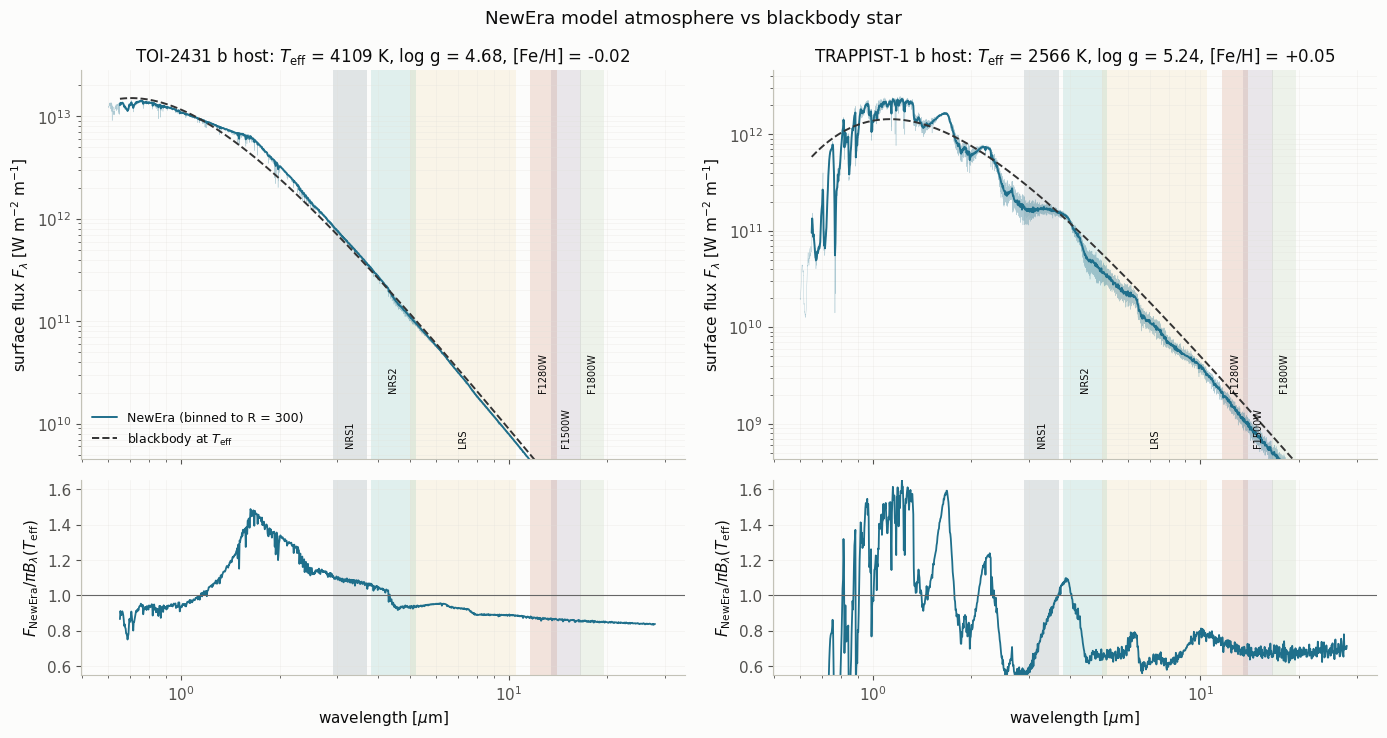

In [4]:
PAPER_MODE = False
fig, axes = plt.subplots(2, len(spec), figsize=(14, 7.5), sharex=True, gridspec_kw=dict(height_ratios=(2, 1)))
for j, (nm, s) in enumerate(spec.items()):
    ax, ax_r = axes[0, j], axes[1, j]
    ax.plot(s["w"] * 1e6, s["F_ne"], color="#1f6f8b", lw=0.3, alpha=0.35)
    ax.plot(lam_b * 1e6, s["Fb_ne"], color="#1f6f8b", lw=1.4, label="NewEra (binned to R = 300)")
    ax.plot(lam_b * 1e6, s["Fb_bb"], "--", color="#333333", lw=1.4, label=r"blackbody at $T_{\rm eff}$")
    ax_r.plot(lam_b * 1e6, s["Fb_ne"] / s["Fb_bb"], color="#1f6f8b", lw=1.3)
    ax_r.axhline(1., color="0.4", lw=0.8)
    for k_, ins in enumerate(SINGLE):
        l1, l2 = filter_lambda(ins)
        for a in (ax, ax_r): a.axvspan(l1 * 1e6, l2 * 1e6, color=INSTRUMENT_COLORS[k_ % len(INSTRUMENT_COLORS)], alpha=0.13, lw=0)
        ax.text(np.sqrt(l1 * l2) * 1e6, 0.03 + 0.14 * (k_ % 2), short(ins), transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=7, rotation=90)   # staggered: adjacent bands overlap
    pl = SPEC_HOSTS[nm]
    ax.set(xscale="log", yscale="log", ylim=(s["Fb_bb"].max() * 3e-4, s["Fb_ne"].max() * 2.), ylabel=r"surface flux $F_\lambda$ [W m$^{-2}$ m$^{-1}$]",
           title=rf"{nm} host: $T_{{\rm eff}}$ = {pl.T2_eff:.0f} K, log g = {pl.logg:.2f}, [Fe/H] = {pl.feh:+.2f}")
    ax_r.set(xlabel=r"wavelength [$\mu$m]", ylabel=r"$F_{\rm NewEra} / \pi B_\lambda(T_{\rm eff})$", ylim=(0.55, 1.65))
    for a in (ax, ax_r): a.grid(alpha=0.3, which="both")
axes[0, 0].legend(fontsize=9)
fig.suptitle("NewEra model atmosphere vs blackbody star")
fig.tight_layout()
paper_figure("stellar_compare_spectra", PAPER_MODE)
plt.show()

### 0.2 What SPIDERMAN integrates in a band

The integrand of the stellar band flux, $I_\lambda\,R_E(\lambda)$, with $R_E = T(\lambda)\,\lambda/hc$ the per-energy response that `fspiderman.get_filter` makes from the photon-counting throughput $T(\lambda)$. Both curves are scaled by the peak of the blackbody one, so their areas compare directly: $k = S_{\rm BB}/S_{\rm NewEra}$. The title gives $k$ from this direct integral at the host's exact $T_{\rm eff}$, and from SPIDERMAN's spline through the stellar grid (section 0.3), which is what the pipeline uses.

The two $k$ agree closely (the spline interpolates between 100 K nodes); in NRS1 the model can carry more flux than the blackbody, in the MIRI bands it carries less.

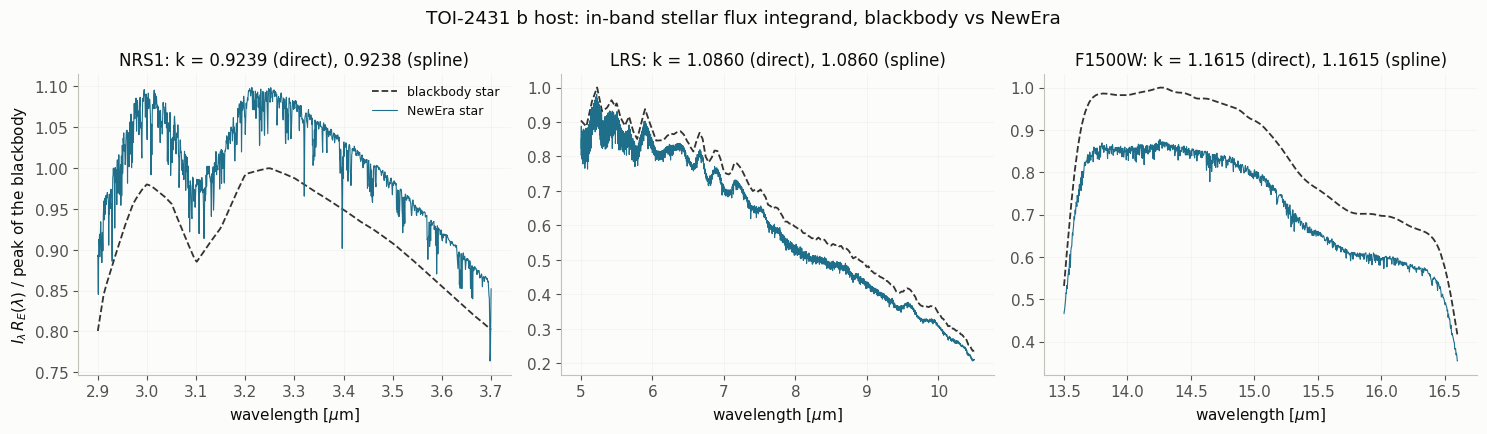

In [5]:
PAPER_MODE = False
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, ins in zip(axes, ["JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1500W"]):
    (l1, l2), (fw, fr) = filter_lambda(ins), sp.get_filter(filter_loc(ins))
    lam = band_wavelengths(np.linspace(l1, l2, 3000), planet.T2_eff, planet.logg, planet.feh, "newera")   # the band refined with the model's own samples
    resp = np.interp(lam, fw, fr)
    integrand = {lab: stellar_intensity(lam, planet.T2_eff, planet.logg, planet.feh, m) * resp for lab, m in MODELS.items()}
    S = {lab: np.trapezoid(v, lam) for lab, v in integrand.items()}
    scale = integrand[BB].max()
    ax.plot(lam * 1e6, integrand[BB] / scale, "--", color="#333333", lw=1.3, label=BB)
    ax.plot(lam * 1e6, integrand[NE] / scale, color="#1f6f8b", lw=0.8, label=NE)
    ax.set(xlabel=r"wavelength [$\mu$m]", title=f"{short(ins)}: k = {S[BB] / S[NE]:.4f} (direct), {k_factor(planet, ins):.4f} (spline)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$I_\lambda\,R_E(\lambda)$ / peak of the blackbody"); axes[0].legend(fontsize=9)
fig.suptitle(f"{planet.name} host: in-band stellar flux integrand, blackbody vs NewEra")
fig.tight_layout()
paper_figure("stellar_compare_integrand", PAPER_MODE)
plt.show()

### 0.3 The stellar grid and SPIDERMAN's spline

`stellar_spidergrid` returns the in-band stellar intensity at the nodes `TEFF_NODES` (uniform, 100 K) for one star (log g, [Fe/H]) and one band. SPIDERMAN puts a cubic spline through it and reads it at the host's $T_{\rm eff}$; `spidergrid_value` is a line-by-line replica of that spline (used by `T_bright`). Top: the nodes and the spline for both stars (the host's $T_{\rm eff}$ dotted); bottom: their ratio $k(T_{\rm eff})$.

What to look for: the spline runs smoothly through the nodes; the NewEra nodes are less smooth than the blackbody ones at the cool end (the grid's seam below ~2900 K), which is why `T_bright` takes the star from this spline rather than interpolating the spectrum.

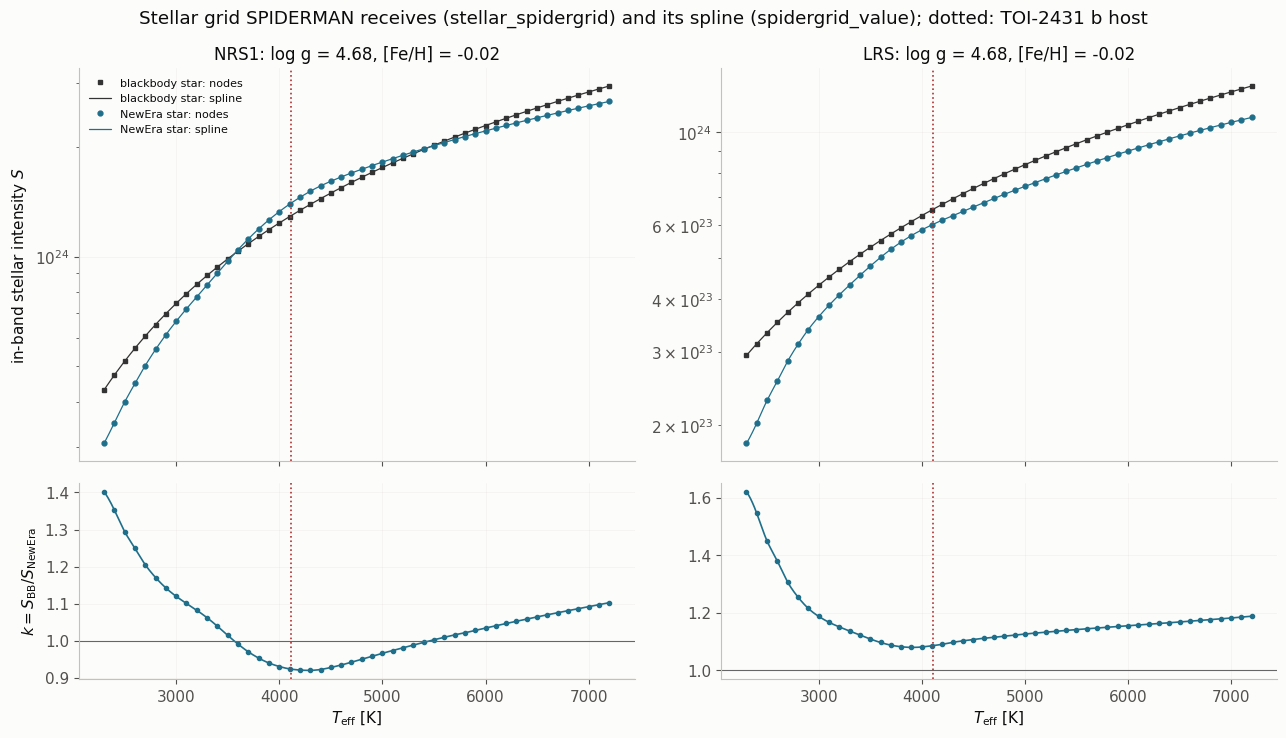

In [6]:
PAPER_MODE = False
T_fine = np.linspace(TEFF_NODES[0], TEFF_NODES[-1], 500)
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, gridspec_kw=dict(height_ratios=(2, 1)))
for j, ins in enumerate(["JWST_NIRSpec.G395H_NRS1", "MIRI/LRS"]):
    g = {lab: stellar_spidergrid(filter_lambda(ins), filter_loc(ins), planet.logg, planet.feh, stellar_model=m) for lab, m in MODELS.items()}
    spl = {lab: np.array([spidergrid_value(g[lab], T) for T in T_fine]) for lab in MODELS}
    for lab, c, mk in ((BB, "#333333", "s"), (NE, "#1f6f8b", "o")):
        axes[0, j].plot(g[lab][0], g[lab][1], mk, ms=3.5, color=c, label=f"{lab}: nodes")
        axes[0, j].plot(T_fine, spl[lab], "-", lw=0.9, color=c, label=f"{lab}: spline")
    axes[1, j].plot(T_fine, spl[BB] / spl[NE], color="#1f6f8b", lw=1.2)
    axes[1, j].plot(g[BB][0], g[BB][1] / g[NE][1], "o", ms=3, color="#1f6f8b")
    axes[1, j].axhline(1., color="0.4", lw=0.8)
    for a in axes[:, j]: a.axvline(planet.T2_eff, color="#b03030", ls=":", lw=1.2); a.grid(alpha=0.3)
    axes[0, j].set(yscale="log", title=f"{short(ins)}: log g = {planet.logg:.2f}, [Fe/H] = {planet.feh:+.2f}")
    axes[1, j].set(xlabel=r"$T_{\rm eff}$ [K]")
axes[0, 0].set_ylabel(r"in-band stellar intensity $S$"); axes[1, 0].set_ylabel(r"$k = S_{\rm BB} / S_{\rm NewEra}$"); axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Stellar grid SPIDERMAN receives (stellar_spidergrid) and its spline (spidergrid_value); dotted: {planet.name} host")
fig.tight_layout()
paper_figure("stellar_compare_grid", PAPER_MODE)
plt.show()

### 0.4 Interpolation in [Fe/H] and log g

$k$ at the host's $T_{\rm eff}$ as a function of [Fe/H] (left, at the host's log g) and of log g (right, at the host's [Fe/H]). `newera_spectrum` interpolates linearly in flux between the cube's models (grey lines), so $k$ is piecewise smooth with kinks at the nodes; the host's own values are dotted.

What to look for: how much a realistic change of [Fe/H] or log g moves $k$ compared with the blackbody-to-NewEra step itself (the distance of the curves from 1).

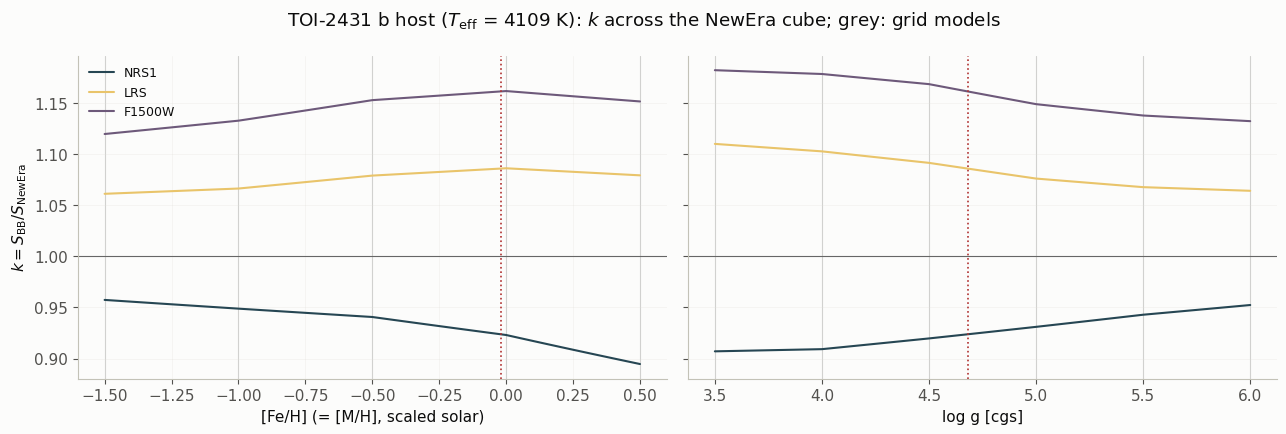

In [7]:
PAPER_MODE = False
def k_at(T, logg, feh, ins):
    lr, fp = filter_lambda(ins), filter_loc(ins)
    return spidergrid_value(stellar_spidergrid(lr, fp, logg, feh, stellar_model="blackbody"), T) / spidergrid_value(stellar_spidergrid(lr, fp, logg, feh, stellar_model="newera"), T)

fe_fine, g_fine = np.linspace(newera_utils.CUBE_FEH[0], newera_utils.CUBE_FEH[-1], 41), np.linspace(newera_utils.CUBE_LOGG[0], newera_utils.CUBE_LOGG[-1], 26)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for k_, ins in enumerate(["JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1500W"]):
    c = INSTRUMENT_COLORS[SINGLE.index(ins) % len(INSTRUMENT_COLORS)]
    axes[0].plot(fe_fine, [k_at(planet.T2_eff, planet.logg, z, ins) for z in fe_fine], "-", color=c, lw=1.5, label=short(ins))
    axes[1].plot(g_fine, [k_at(planet.T2_eff, g, planet.feh, ins) for g in g_fine], "-", color=c, lw=1.5)
for z in newera_utils.CUBE_FEH: axes[0].axvline(z, color="0.8", lw=0.8, zorder=0)
for g in newera_utils.CUBE_LOGG: axes[1].axvline(g, color="0.8", lw=0.8, zorder=0)
axes[0].axvline(planet.feh, color="#b03030", ls=":", lw=1.2); axes[1].axvline(planet.logg, color="#b03030", ls=":", lw=1.2)
axes[0].set(xlabel="[Fe/H] (= [M/H], scaled solar)", ylabel=r"$k = S_{\rm BB} / S_{\rm NewEra}$"); axes[1].set(xlabel="log g [cgs]")
for a in axes: a.axhline(1., color="0.4", lw=0.8); a.grid(alpha=0.3)
axes[0].legend(fontsize=9)
fig.suptitle(rf"{planet.name} host ($T_{{\rm eff}}$ = {planet.T2_eff:.0f} K): $k$ across the NewEra cube; grey: grid models")
fig.tight_layout()
paper_figure("stellar_compare_interp", PAPER_MODE)
plt.show()

### 0.5 `T_bright` as the inverse of the depth

The occultation depth of a uniform planet at temperature $T$, $(r_1/r_2)^2\,$`band_planck`$(T)\,/\,S_\star$, with $S_\star$ from `spidergrid_value` for each star; `T_bright` solves exactly this for $T$. Horizontal lines: the model (hyperillumination) depths of the target with each star; vertical lines: their brightness temperatures, and the brightness temperature the blackbody-star depth gets when it is read as a measurement with the NewEra star.

What to look for: each star's model depth lands on the same $T$ on its own curve (the star cancels), while reading one depth with the other star's curve moves $T$: lower in the mid-IR (where $k > 1$), higher where $k < 1$.

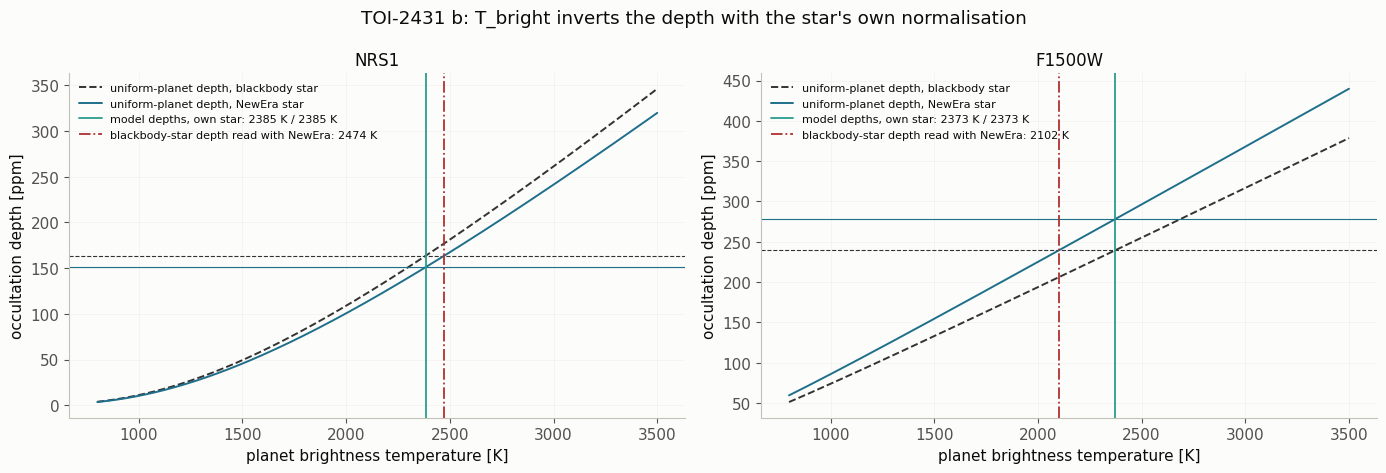

In [8]:
PAPER_MODE = False
T_p = np.linspace(800., 3500., 300)
rp2 = (planet.r1 / planet.r2) ** 2
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, ins in zip(axes, ["JWST_NIRSpec.G395H_NRS1", "MIRI/F1500W"]):
    lr, fp = filter_lambda(ins), filter_loc(ins)
    d_model = {lab: thermal_PhaseCurve(planet, lr, t=np.array([0.5 * planet.period]), u_B=u_B, A_B=A_B_true, filter_path=fp, insolation_model="hyperillum",
                                       include_transit=False, spman="normal", stellar_model=m)[2] for lab, m in MODELS.items()}
    for lab, m, ls, c in ((BB, "blackbody", "--", "#333333"), (NE, "newera", "-", "#1f6f8b")):
        S_star = spidergrid_value(stellar_spidergrid(lr, fp, planet.logg, planet.feh, stellar_model=m), planet.T2_eff)
        ax.plot(T_p, [1e6 * rp2 * band_planck(lr, fp, T) / S_star for T in T_p], ls, color=c, lw=1.4, label=f"uniform-planet depth, {lab}")
        ax.axhline(d_model[lab], color=c, ls=ls, lw=0.8)
    T_own = {lab: T_bright(d_model[lab], planet, lr, filter_path=fp, stellar_model=m) for lab, m in MODELS.items()}
    T_meas = T_bright(d_model[BB], planet, lr, filter_path=fp, stellar_model="newera")
    ax.axvline(T_own[NE], color="#2a9d8f", lw=1.3, label=f"model depths, own star: {T_own[BB]:.0f} K / {T_own[NE]:.0f} K")
    ax.axvline(T_meas, color="#b03030", lw=1.3, ls="-.", label=f"blackbody-star depth read with NewEra: {T_meas:.0f} K")
    ax.set(xlabel="planet brightness temperature [K]", ylabel="occultation depth [ppm]", title=short(ins)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle(f"{planet.name}: T_bright inverts the depth with the star's own normalisation")
fig.tight_layout()
paper_figure("stellar_compare_tbright", PAPER_MODE)
plt.show()

### 0.6 Which hosts the stellar grid covers

The NewEra cube spans the ranges of `newera_utils.CUBE_*` and SPIDERMAN's nodes `TEFF_NODES`. A host outside them cannot get a NewEra spectrum: `planet_bias_table` and `planet_false_F_table` leave such planets out with a note (`drop_unsupported_hosts`) instead of aborting. The cell counts the covered archive hosts (missing log g / [Fe/H] counted at their fallback values) and runs `drop_unsupported_hosts` on the target plus one archive planet per failure mode.

What to look for: the rocky sample is covered; the planets left out are evolved, hot or very metal-rich hosts.

In [9]:
import HItargets_utils as hit
arch = hit._archive(); valid = arch[arch["hyperillum_valid"]]; rocky = valid["pl_rade"] < 1.7
reasons = {"T_eff outside TEFF_NODES": ~valid["st_teff"].between(TEFF_NODES[0], TEFF_NODES[-1]),
           "log g outside the cube": ~valid["st_logg"].fillna(4.5).between(newera_utils.CUBE_LOGG[0], newera_utils.CUBE_LOGG[-1]),
           "[Fe/H] outside the cube": ~valid["st_met"].fillna(0.).between(newera_utils.CUBE_FEH[0], newera_utils.CUBE_FEH[-1])}
covered = ~np.logical_or.reduce(list(reasons.values()))
print(f"covered: {covered.sum()} of {len(valid)} valid archive planets, {(covered & rocky).sum()} of {rocky.sum()} rocky ones; " + ", ".join(f"{r}: {m.sum()}" for r, m in reasons.items()))
examples = [valid.loc[m & valid["st_teff"].notna(), "pl_name"].iloc[0] for m in reasons.values()]
kept = drop_unsupported_hosts(cfgs[NE], [planet] + list(hi_planets_by_name(examples).values()))
print("kept:", [p.name for p in kept])

covered: 4635 of 4685 valid archive planets, 1265 of 1265 rocky ones; T_eff outside TEFF_NODES: 27, log g outside the cube: 15, [Fe/H] outside the cube: 8
no stellar spectrum for 3 of 4 planets, left out of the table:
  MASCARA-1 b (T_s = 7490 K outside the stellar grid nodes [2300, 7200] K: SPIDERMAN's spline would extrapolate silently)
  TOI-4377 b (NewEra cube: logg = 3.39 outside [3.5, 6.0]; widen CUBE_* in newera_utils and rebuild)
  Kepler-975 c (NewEra cube: [M/H] = 0.56 outside [-1.5, 0.5]; widen CUBE_* in newera_utils and rebuild)
kept: ['TOI-2431 b']


## 1. The depth multiplier $k$ for every host and band

$k = S_{\rm BB}/S_{\rm NewEra}$ at the host's $T_{\rm eff}$, from SPIDERMAN's own spline through the two stellar grids (`spidergrid_value`): a thermal depth with the NewEra star is $k$ times the blackbody-star value. Hosts: those of `NightsideTemperature.ipynb` plus two M dwarfs.

What to look for: $k > 1$ in the mid-IR (a real star is fainter there than a blackbody, because H$^-$ free-free opacity puts the mid-IR photosphere higher and cooler), growing towards the coolest hosts; $k$ around or below 1 in NRS1 for K stars (the model's near-IR flux exceeds the blackbody).

In [10]:
HOSTS = [*PAPER_PLANETS, "LHS 3844 b", "TRAPPIST-1 b"]   # the planets of the paper and two cool hosts
hosts = hi_planets_by_name(HOSTS)

k_tab = pd.DataFrame([{"host": nm, "T_eff": pl.T2_eff, "logg": pl.logg, "[Fe/H]": pl.feh, **{short(ins): k_factor(pl, ins) for ins in SINGLE}} for nm, pl in hosts.items()]).sort_values("T_eff")
print(k_tab.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

        host    T_eff  logg  [Fe/H]  NRS1  NRS2   LRS  F1280W  F1500W  F1800W
TRAPPIST-1 b 2566.000 5.240   0.052 1.282 1.199 1.484   1.418   1.474   1.481
  LHS 3844 b 3080.000 5.070   0.220 1.102 1.038 1.175   1.200   1.209   1.206
  TOI-2431 b 4109.000 4.680  -0.020 0.924 1.008 1.086   1.150   1.162   1.173
    K2-141 b 4599.000 4.620  -0.060 0.936 1.039 1.112   1.176   1.188   1.201
 Kepler-78 b 5058.000 4.550  -0.180 0.974 1.066 1.130   1.188   1.199   1.211
 TOI-1798.02 5106.000 4.572   0.073 0.974 1.068 1.130   1.188   1.199   1.211
    K2-131 b 5120.000 4.620  -0.040 0.976 1.068 1.131   1.188   1.200   1.212
   TOI-561 b 5372.000 4.500  -0.400 1.000 1.080 1.141   1.195   1.205   1.215
  TOI-1444 b 5430.000 4.490   0.130 0.997 1.083 1.140   1.193   1.203   1.215
  TOI-2260 b 5534.000 4.620   0.220 1.002 1.085 1.141   1.194   1.203   1.215
  HD 80653 b 5959.000 4.342   0.255 1.031 1.100 1.153   1.204   1.212   1.223


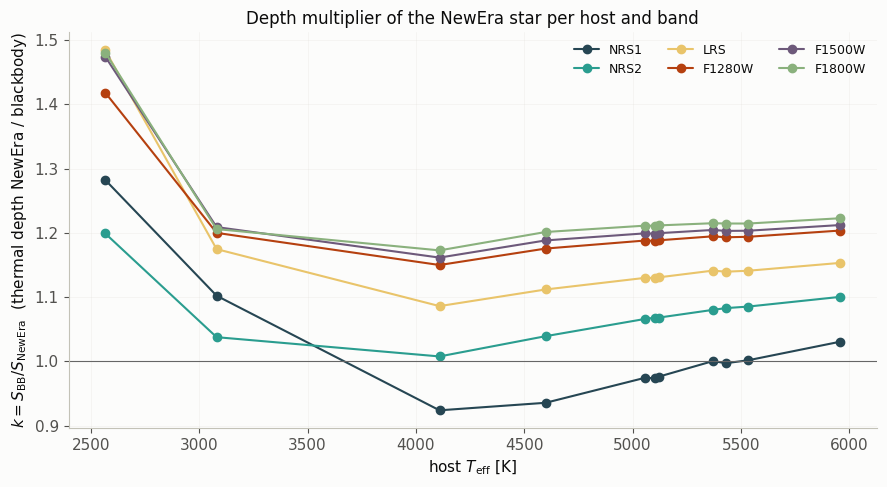

In [11]:
PAPER_MODE = False
fig, ax = plt.subplots(figsize=(9, 5))
for k_, ins in enumerate(SINGLE):
    ax.plot(k_tab["T_eff"], k_tab[short(ins)], "o-", color=INSTRUMENT_COLORS[k_ % len(INSTRUMENT_COLORS)], label=short(ins))
ax.axhline(1, color="0.4", lw=0.8)
ax.set(xlabel=r"host $T_{\rm eff}$ [K]", ylabel=r"$k = S_{\rm BB} / S_{\rm NewEra}$  (thermal depth NewEra / blackbody)", title="Depth multiplier of the NewEra star per host and band")
ax.grid(alpha=0.3); ax.legend(ncol=3, fontsize=9)
fig.tight_layout()
paper_figure("stellar_compare_k", PAPER_MODE)
plt.show()

## 2. Phase curves

Full phase curves (transit, reflected and thermal light) of the target with the hyperillumination model on every single-detector band, for both stars, and below them the **hyperillumination signal** $\Delta F = F_{\rm hyperillum} - F_{\rm naive}$ at the same $A_B$, the part of the curve the point-source models cannot reproduce and the origin of the bias. Its ratio between the two stars is printed per band.

What to look for: the curves differ only where thermal emission matters (largest near occultation, in the mid-IR bands); the transit and the reflected part are identical; the hyperillumination signal is scaled by $k$ of section 1.

In [12]:
t = np.linspace(0., planet.period, 600, endpoint=False)
phase = t / planet.period
curves = {}   # (band, star, insolation model) -> full curve [ppm]
for ins in SINGLE:
    lr, fp = filter_lambda(ins), filter_loc(ins)
    for lab, m in MODELS.items():
        for model in ("hyperillum", "naive"):
            _, total, _ = full_PhaseCurve(planet, lr, t=t, u=u, u_B=u_B, A=A_model(A_B_true), A_B=A_B_true, filter_path=fp, insolation_model=model, stellar_model=m)
            curves[(short(ins), lab, model)] = (total - 1.) * 1e6
for ins in SINGLE:
    s = short(ins)
    d_bb, d_ne = (curves[(s, lab, "hyperillum")] - curves[(s, lab, "naive")] for lab in (BB, NE))
    i = np.argmax(np.abs(d_bb))
    print(f"{s:7s} hyperillumination signal at its peak: {d_bb[i]:+.2f} ppm ({BB}) vs {d_ne[i]:+.2f} ppm ({NE}), ratio {d_ne[i]/d_bb[i]:.4f}; k = {k_factor(planet, ins):.4f}")

NRS1    hyperillumination signal at its peak: +8.12 ppm (blackbody star) vs +7.51 ppm (NewEra star), ratio 0.9255; k = 0.9238
NRS2    hyperillumination signal at its peak: +11.46 ppm (blackbody star) vs +11.55 ppm (NewEra star), ratio 1.0075; k = 1.0077
LRS     hyperillumination signal at its peak: +17.54 ppm (blackbody star) vs +19.03 ppm (NewEra star), ratio 1.0851; k = 1.0860
F1280W  hyperillumination signal at its peak: +23.84 ppm (blackbody star) vs +27.38 ppm (NewEra star), ratio 1.1488; k = 1.1500
F1500W  hyperillumination signal at its peak: +25.26 ppm (blackbody star) vs +29.31 ppm (NewEra star), ratio 1.1604; k = 1.1615
F1800W  hyperillumination signal at its peak: +26.67 ppm (blackbody star) vs +31.25 ppm (NewEra star), ratio 1.1716; k = 1.1727


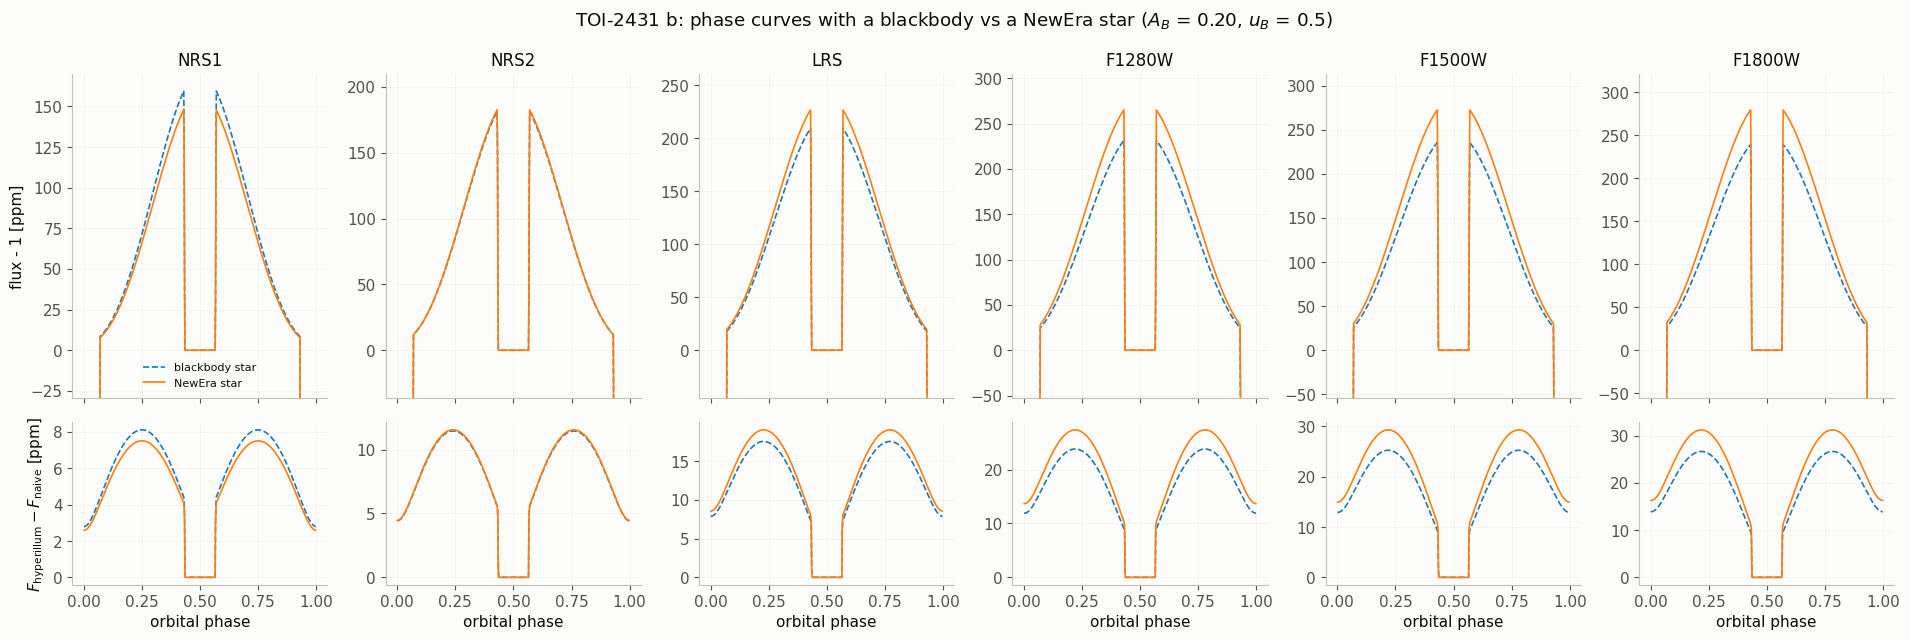

In [13]:
PAPER_MODE = False
fig, axes = plt.subplots(2, len(SINGLE), figsize=(3.2 * len(SINGLE), 6.5), sharex=True, gridspec_kw=dict(height_ratios=(2, 1)))
for j, ins in enumerate(SINGLE):
    s = short(ins)
    for lab, ls in ((BB, "--"), (NE, "-")):
        axes[0, j].plot(phase, curves[(s, lab, "hyperillum")], ls, lw=1.2, label=lab)
        axes[1, j].plot(phase, curves[(s, lab, "hyperillum")] - curves[(s, lab, "naive")], ls, lw=1.2, label=lab)
    axes[0, j].set_ylim(-0.2 * np.max(curves[(s, NE, "hyperillum")]), 1.15 * np.max(curves[(s, NE, "hyperillum")]))   # the transit dips far below; zoom on the phase curve
    axes[0, j].set_title(s); axes[1, j].set_xlabel("orbital phase")
    for a in axes[:, j]: a.grid(alpha=0.3)
axes[0, 0].set_ylabel("flux - 1 [ppm]"); axes[1, 0].set_ylabel(r"$F_{\rm hyperillum} - F_{\rm naive}$ [ppm]")
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"{planet.name}: phase curves with a blackbody vs a NewEra star ($A_B$ = {A_B_true:.2f}, $u_B$ = {u_B})")
fig.tight_layout()
paper_figure("stellar_compare_phasecurves", PAPER_MODE)
plt.show()

## 3. Occultation depths and brightness temperatures

Per band: the thermal occultation depth with each star, their ratio ($= k$), the brightness temperature of each model depth with its own star, and the brightness temperature that the **blackbody-star depth** gets when it is read as a measurement and converted with the NewEra star.

What to look for: the two model brightness temperatures agree (the star cancels between forward model and inversion), while reading the same depth with a different star does not: that is the difference between a model depth and a measured depth.

In [14]:
rows = []
for ins in SINGLE:
    lr, fp = filter_lambda(ins), filter_loc(ins)
    d = {lab: thermal_PhaseCurve(planet, lr, t=np.array([0.5 * planet.period]), u_B=u_B, A_B=A_B_true, filter_path=fp, insolation_model="hyperillum", include_transit=False, spman="normal", stellar_model=m)[2]
         for lab, m in MODELS.items()}
    rows.append(dict(band=short(ins), depth_BB=d[BB], depth_NE=d[NE], ratio=d[NE] / d[BB],
                     T_bright_BB=T_bright(d[BB], planet, lr, filter_path=fp, stellar_model="blackbody"), T_bright_NE=T_bright(d[NE], planet, lr, filter_path=fp, stellar_model="newera"),
                     T_bright_BBdepth_with_NE=T_bright(d[BB], planet, lr, filter_path=fp, stellar_model="newera")))
print(f"{planet.name}, hyperillumination model, A_B = {A_B_true}: thermal depths [ppm] and brightness temperatures [K]")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3f}" if abs(v) < 10 else f"{v:.1f}"))

TOI-2431 b, hyperillumination model, A_B = 0.2: thermal depths [ppm] and brightness temperatures [K]
  band  depth_BB  depth_NE  ratio  T_bright_BB  T_bright_NE  T_bright_BBdepth_with_NE
  NRS1     163.8     151.3  0.924       2384.9       2384.9                    2474.1
  NRS2     185.8     187.3  1.008       2380.3       2380.3                    2370.6
   LRS     213.9     232.3  1.086       2375.6       2375.6                    2249.4
F1280W     235.6     270.9  1.150       2373.7       2373.7                    2127.2
F1500W     239.6     278.3  1.162       2373.5       2373.5                    2101.9
F1800W     243.3     285.4  1.173       2373.2       2373.2                    2076.5


## 4. Retrieved $A_B$ per instrument, with Fisher $\sigma$

The hyperillumination truth at $A_B$ = `A_B_true` fitted on every instrument (`instrument_retrievals`, the planet's own geometry and PandExo noise, a joint fit for the NRS1 + NRS2 tuple), with the $A_B$-only model and with the joint $A_B$ + $F$ model, for both stars. Markers: fitted $A_B$; bars: Fisher $1\sigma$ / $2\sigma$; dashed: the injected value.

What to look for: the points (the bias) sit at the same place for both stars, while the bars are narrower where $k > 1$ (mid-IR) and wider where $k < 1$ (NRS1); the table prints the bias change, the $\sigma$ ratio (expected $1/k$) and both verdicts.

In [15]:
tab_AB = {BB: instrument_retrievals(cfgs[BB], planet, INSTRUMENTS, A_B_true, **kw)}
sigma_inst = tab_AB[BB].attrs["sigma_1min"]   # PandExo noise, independent of the stellar SED: reused for the NewEra star and every later section
tab_AB[NE] = instrument_retrievals(cfgs[NE], planet, INSTRUMENTS, A_B_true, sigma_1min=sigma_inst, **kw)
tab_J = {lab: instrument_retrievals(cfgs[lab], planet, INSTRUMENTS, A_B_true, redist=True, sigma_1min=sigma_inst, **kw) for lab in MODELS}

def compare(tabs, key, cols):
    a, b = (tabs[lab].set_index(key) for lab in (BB, NE))
    out = pd.DataFrame({f"{c}_BB": a[c] for c in cols} | {f"{c}_NE": b[c] for c in cols})
    out = out[[f"{c}_{s}" for c in cols for s in ("BB", "NE")]]
    return out

for name, tabs in (("A_B-only fit", tab_AB), ("joint A_B + F fit", tab_J)):
    cols = ["bias_A_B", "sigma_A_B", "bias_sigma", "verdict"] + (["F_fit", "sigma_F"] if "joint" in name else [])
    cmp_ = compare(tabs, "instrument", cols)
    cmp_.insert(2, "d_bias", cmp_["bias_A_B_NE"] - cmp_["bias_A_B_BB"]); cmp_.insert(5, "sigma_ratio", cmp_["sigma_A_B_NE"] / cmp_["sigma_A_B_BB"])
    print(f"--- {name} ({planet.name}, A_B_true = {A_B_true}, {n_orbits} orbits)")
    print(cmp_.rename(index=short).to_string(float_format=fmt))
    print()

--- A_B-only fit (TOI-2431 b, A_B_true = 0.2, 5 orbits)
            bias_A_B_BB  bias_A_B_NE     d_bias  sigma_A_B_BB  sigma_A_B_NE  sigma_ratio  bias_sigma_BB  bias_sigma_NE        verdict_BB        verdict_NE
instrument                                                                                                                                                
NRS1           -0.03862     -0.03873 -0.0001105       0.03192       0.03455        1.083           1.21          1.121  needs hyperillum  needs hyperillum
NRS2           -0.04778     -0.04777  1.029e-05       0.04183       0.04151       0.9924          1.142          1.151  needs hyperillum  needs hyperillum
NRS1+NRS2      -0.04205     -0.04245 -0.0004061       0.02537       0.02655        1.047          1.657          1.599  needs hyperillum  needs hyperillum
LRS            -0.05989     -0.05978  0.0001158       0.05765       0.05308       0.9207          1.039          1.126  needs hyperillum  needs hyperillum
F1280W        

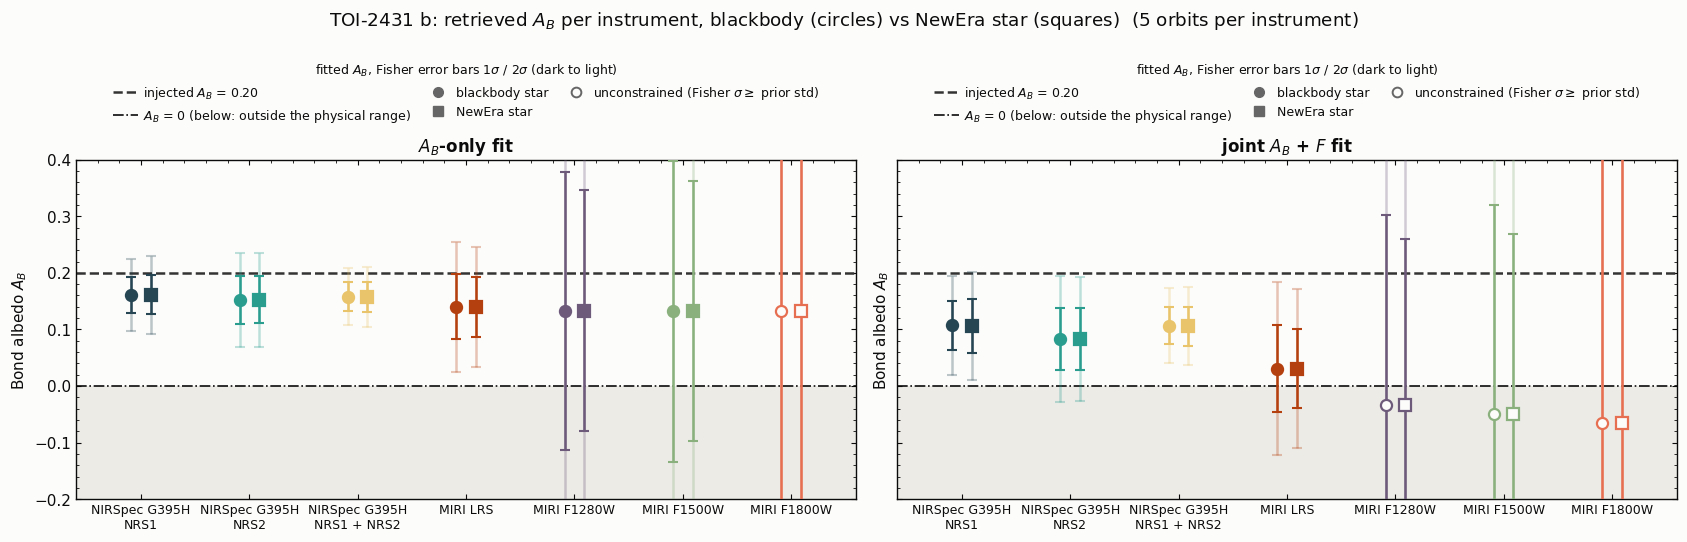

In [16]:
PAPER_MODE = False
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
ylim = retrieval_ylim([*tab_AB.values(), *tab_J.values()])   # one range for both panels (shared y axis), so both draw the A_B < 0 band
plot_instrument_retrievals(tab_AB, ax=axes[0], ylim=ylim, title=r"$A_B$-only fit")
plot_instrument_retrievals(tab_J, ax=axes[1], ylim=ylim, title=r"joint $A_B$ + $F$ fit")
fig.suptitle(f"{planet.name}: retrieved $A_B$ per instrument, blackbody (circles) vs NewEra star (squares)  ({n_orbits} orbits per instrument)")
fig.tight_layout()
paper_figure("stellar_compare_retrievals", PAPER_MODE)
plt.show()

## 5. Occultation depth of the fits

The fits of section 4 seen through the observable (`instrument_depths`, no refit): fitted against true occultation depth per band, with the propagated Fisher $\sigma$, for both stars.

What to look for: the true and fitted depths and the depth bias scale by $k$, while the depth's Fisher $\sigma$ is the same for both stars (the noise sets it; $\sigma_{A_B} \propto 1/k$ and $\partial\delta/\partial A_B \propto k$ cancel), so `depth_bias_sigma` scales with $k$.

In [17]:
dep = {lab: instrument_depths(cfgs[lab], planet, tab_AB[lab], **kw) for lab in MODELS}
cmp_ = compare(dep, "instrument", ["depth_true", "depth_fit", "bias_depth", "sigma_depth", "depth_bias_sigma"])
cmp_.insert(2, "true_ratio", cmp_["depth_true_NE"] / cmp_["depth_true_BB"])
print(f"{planet.name}, A_B-only fits: occultation depths [ppm]")
print(cmp_.rename(index=short).to_string(float_format=fmt))

TOI-2431 b, A_B-only fits: occultation depths [ppm]
            depth_true_BB  depth_true_NE  true_ratio  depth_fit_BB  depth_fit_NE  bias_depth_BB  bias_depth_NE  sigma_depth_BB  sigma_depth_NE  depth_bias_sigma_BB  depth_bias_sigma_NE
instrument                                                                                                                                                                              
NRS1                170.5            158      0.9268         171.9         159.3          1.378          1.275           3.374           3.374               0.4085                0.378
NRS2                192.6            194       1.007         194.3         195.7          1.697           1.71           4.234           4.234               0.4009               0.4039
LRS                 220.6            239       1.083         222.5           241          1.856          2.014            5.36            5.36               0.3464               0.3758
F1280W              242

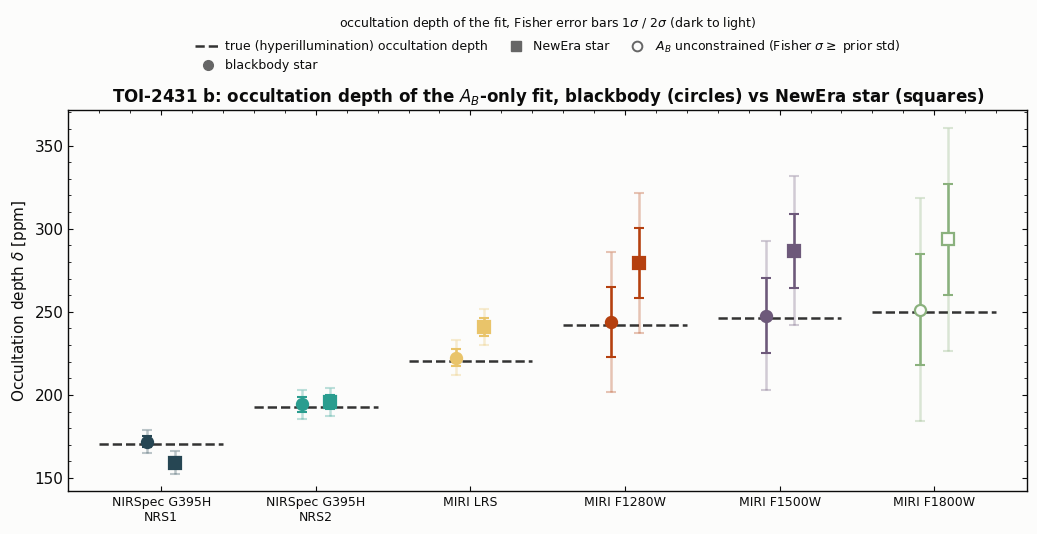

In [18]:
PAPER_MODE = False
fig, ax = plot_instrument_retrievals(dep, quantity="depth", title=f"{planet.name}: occultation depth of the $A_B$-only fit, blackbody (circles) vs NewEra star (squares)")
paper_figure("stellar_compare_depths", PAPER_MODE, fig=fig)
plt.show()

## 6. False-positive heat redistribution per instrument

$z_F = \sqrt{\Delta\chi^2_F}$, the expected significance of the spurious $F$ when the hyperillumination truth is fitted with the joint model (`instrument_false_F`, same noise for both stars), and the verdict against $z = 2$.

What to look for: the fitted $F$ is unchanged in thermal-dominated bands, while $z_F$ scales with $k$ ($\Delta\chi^2_F$ with $k^2$), so a verdict can flip near the threshold.

In [19]:
z_false = 2.
tab_FP = {lab: instrument_false_F(cfgs[lab], planet, INSTRUMENTS, A_B_true, z=z_false, sigma_1min=sigma_inst, **kw) for lab in MODELS}
cmp_ = compare(tab_FP, "instrument", ["F_fit", "dchi2_F", "z_F", "verdict"])
cmp_.insert(6, "z_ratio", cmp_["z_F_NE"] / cmp_["z_F_BB"])
print(f"{planet.name}: spurious F per instrument (threshold z = {z_false:g})")
print(cmp_.rename(index=short).to_string(float_format=fmt))

TOI-2431 b: spurious F per instrument (threshold z = 2)
            F_fit_BB  F_fit_NE  dchi2_F_BB  dchi2_F_NE  z_F_BB  z_F_NE  z_ratio       verdict_BB       verdict_NE
instrument                                                                                                       
NRS1         0.01941   0.01943       3.249       2.781   1.802   1.668   0.9253  below threshold  below threshold
NRS2         0.01279   0.01279       4.276       4.341   2.068   2.083    1.008   false positive   false positive
NRS1+NRS2    0.01425   0.01402       6.433       6.118   2.536   2.474   0.9752   false positive   false positive
LRS         0.005816  0.005813       6.803       8.013   2.608   2.831    1.085   false positive   false positive
F1280W      0.002516  0.002514      0.8873       1.172   0.942   1.082    1.149  below threshold  below threshold
F1500W      0.002006  0.002005      0.8901       1.199  0.9434   1.095    1.161  below threshold  below threshold
F1800W      0.001576  0.001575  

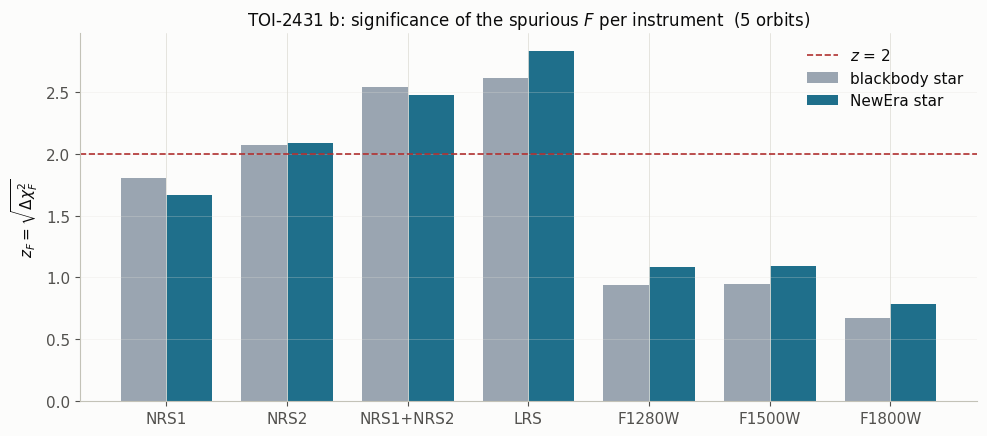

In [20]:
PAPER_MODE = False
labels = [short(ins) for ins in tab_FP[BB]["instrument"]]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 4.5))
for j, lab in enumerate(MODELS):
    ax.bar(x + (j - 0.5) * 0.38, tab_FP[lab]["z_F"], width=0.38, label=lab, color=("#9aa5b1", "#1f6f8b")[j])
ax.axhline(z_false, color="#b03030", ls="--", lw=1.2, label=rf"$z$ = {z_false:g}")
ax.set(xticks=x, xticklabels=labels, ylabel=r"$z_F = \sqrt{\Delta\chi^2_F}$", title=f"{planet.name}: significance of the spurious $F$ per instrument  ({n_orbits} orbits)")
ax.legend(); ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
paper_figure("stellar_compare_falseF", PAPER_MODE)
plt.show()

## 7. Per-planet decisions: the closest-in rocky planets

The planets of the paper (`PAPER_PLANETS`, as in `Bias_Maps.ipynb` 1.2), each fitted at its own geometry and PandExo noise on MIRI/LRS with the $A_B$-only model, for both stars. The table adds each host's $k$ in that band.

What to look for: unchanged biases, $\sigma$ scaled by $1/k$ per host, and any planet whose verdict changes between the two stars.

In [21]:
cfg_lrs = {lab: cfgs[lab] for lab in MODELS}   # the cfgs already carry the MIRI/LRS band
planets_paper = hi_planets_by_name(PAPER_PLANETS)
sigma_paper = rms_1min_pandexo_sample(PAPER_PLANETS, "MIRI/LRS")   # from the PandExo cache where possible
tab_pl = {lab: planet_bias_table(cfg_lrs[lab], A_B_true, PAPER_PLANETS, sigma_paper, AGG=AGG, **kw) for lab in MODELS}
cmp_ = compare(tab_pl, "name", ["bias_A_B", "sigma_A_B", "bias_sigma", "verdict"])
cmp_.insert(0, "k_LRS", [k_factor(planets_paper[nm], "MIRI/LRS") for nm in cmp_.index])
cmp_.insert(5, "sigma_ratio", cmp_["sigma_A_B_NE"] / cmp_["sigma_A_B_BB"])
print(f"MIRI/LRS, A_B-only fit, A_B_true = {A_B_true}, {n_orbits} orbits")
print(cmp_.to_string(float_format=fmt))
flips = cmp_[cmp_["verdict_BB"] != cmp_["verdict_NE"]]
print(f"\nverdict changes: {', '.join(f'{nm} ({r.verdict_BB} -> {r.verdict_NE})' for nm, r in flips.iterrows()) or 'none'}")

MIRI/LRS, A_B-only fit, A_B_true = 0.2, 5 orbits
             k_LRS  bias_A_B_BB  bias_A_B_NE  sigma_A_B_BB  sigma_A_B_NE  sigma_ratio  bias_sigma_BB  bias_sigma_NE        verdict_BB        verdict_NE
name                                                                                                                                                   
TOI-2431 b   1.086     -0.05989     -0.05978       0.05765       0.05308       0.9207          1.039          1.126  needs hyperillum  needs hyperillum
TOI-2260 b   1.141     -0.02834     -0.02822        0.1515        0.1328       0.8763          0.187         0.2126          naive OK          naive OK
K2-141 b     1.112     -0.06379     -0.06373       0.09487       0.08532       0.8993         0.6724          0.747          naive OK          naive OK
K2-131 b     1.131     -0.04192     -0.04181        0.2321        0.2053       0.8843         0.1806         0.2037          naive OK          naive OK
TOI-561 b    1.141     -0.04283     -0.

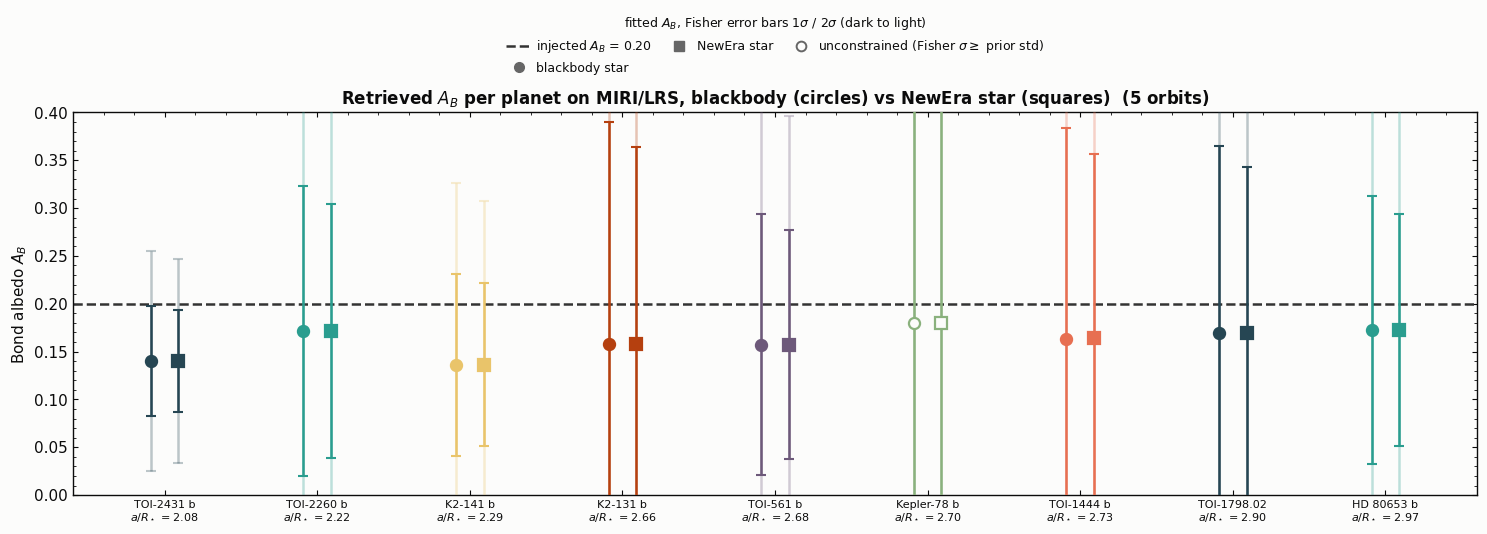

In [22]:
PAPER_MODE = False
fig, ax = plot_planet_retrievals({lab: tab_pl[lab] for lab in MODELS}, planets=PAPER_PLANETS,
                                     title=f"Retrieved $A_B$ per planet on MIRI/LRS, blackbody (circles) vs NewEra star (squares)  ({n_orbits} orbits)")
paper_figure("stellar_compare_planets", PAPER_MODE, fig=fig)
plt.show()

## 8. Bias map over $(a/R_\star, T_{\rm eff})$

A coarse version of the `Bias_Maps.ipynb` 1.1 map (reference geometry, $A_B$-only fit with reflected light, MIRI/LRS) for both stars and their difference. The map holds log g and [Fe/H] of the reference star fixed while $T_{\rm eff}$ is swept (see `swept_planet`).

What to look for: the two maps are indistinguishable by eye; the difference panel shows how small the change from the reflected-light weighting is compared with the bias itself.

In [23]:
a_rs_grid = map_grid(1.5, 4.0, 8)
T_eff_grid = map_grid(3000., 6000., 6, bounds=(TEFF_NODES[0], TEFF_NODES[-1]))
ref = reference_planet(rp_rs=0.015, T_eff=4000., incl=90.)
bmap = {lab: bias_map_grid(replace(cfgs[lab], planet=ref), A_B_true, a_rs_grid, T_eff_grid, "T_s", **kw) for lab in MODELS}
diff = bmap[NE] - bmap[BB]
print(f"bias range {np.nanmin(bmap[BB]):+.4f} .. {np.nanmax(bmap[BB]):+.4f} ({BB}); NewEra - blackbody: {np.nanmin(diff):+.2e} .. {np.nanmax(diff):+.2e}, "
      f"max |relative change| {np.nanmax(np.abs(diff / bmap[BB])):.2e}")

bias range -0.3019 .. -0.0089 (blackbody star); NewEra - blackbody: -2.24e-05 .. +1.40e-03, max |relative change| 5.69e-03


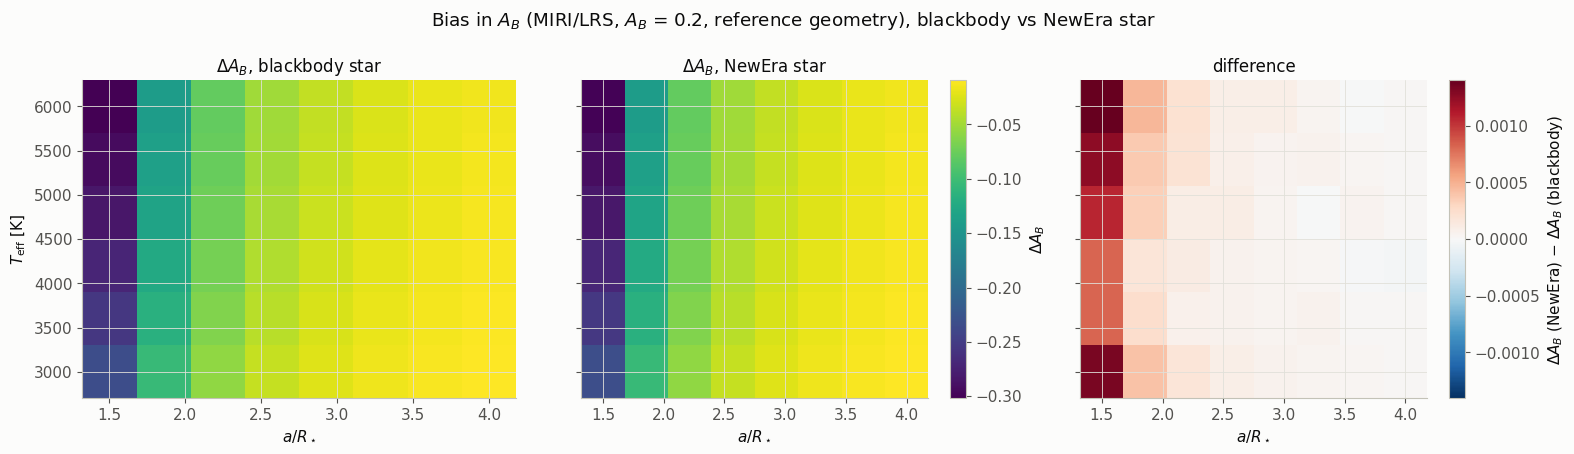

In [24]:
PAPER_MODE = False
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
vmin, vmax = np.nanmin([bmap[BB], bmap[NE]]), np.nanmax([bmap[BB], bmap[NE]])
for ax, lab in zip(axes[:2], MODELS):
    m = ax.pcolormesh(a_rs_grid, T_eff_grid, bmap[lab], shading="nearest", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set(title=rf"$\Delta A_B$, {lab}", xlabel=r"$a/R_\star$")
fig.colorbar(m, ax=axes[1], label=r"$\Delta A_B$")
lim = np.nanmax(np.abs(diff))
m = axes[2].pcolormesh(a_rs_grid, T_eff_grid, diff, shading="nearest", cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.colorbar(m, ax=axes[2], label=r"$\Delta A_B$ (NewEra) $-$ $\Delta A_B$ (blackbody)")
axes[2].set(title="difference", xlabel=r"$a/R_\star$"); axes[0].set_ylabel(r"$T_{\rm eff}$ [K]")
fig.suptitle(f"Bias in $A_B$ (MIRI/LRS, $A_B$ = {A_B_true}, reference geometry), blackbody vs NewEra star")
fig.tight_layout()
paper_figure("stellar_compare_biasmap", PAPER_MODE)
plt.show()